## My Question
If a golfer takes 10 putt attempts from 10 feet away, what is the binomial probability distribution of the total number of successful putts made? What are the expected value (mean) and standard deviation of total putts made, and what is the estimated probability of making at least 7 putts?

## My Simulation
Describe your simulation here:
1. Random Variable ($X$): $X$ is the total number of successful putts made out of 10 attempts. It can be any whole number from 0 to 10. 
2. Trial and Outcomes: One trial is taking 10 putts. The outcome is the total number of putts made (0 to 10).

### My Analysis

In [67]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

In [68]:
results = []
n = 10
p = 0.40
num_simulations = 1000

In [69]:
for i in range(1000):
    made_putts = 0
    for attempt in range(10):
        if random.random() < 0.40:  # 40% chance of making the putt pro's avg
            made_putts += 1
    results.append(made_putts)

In [70]:
mean_putts = np.mean(results)
std_putts = np.std(results)

In [71]:
at_least_7 = sum(1 for x in results if x >= 7)
prob_at_least_7 = (at_least_7 / 1000) * 100

In [72]:
empirical_mean = np.mean(results)
empirical_std = np.std(results)
empirical_count_7_plus = sum(1 for x in results if x >= 7)
empirical_prob_7_plus = empirical_count_7_plus / num_simulations

In [73]:
theoretical_mean = n * p
theoretical_std = np.sqrt(n * p * (1 - p))
theoretical_prob_7_plus = 1 - binom.cdf(6, n, p)

In [74]:
print("=== EMPIRICAL (SIMULATED) ===")
print(f"Empirical Mean: {empirical_mean:.2f}")
print(f"Empirical Standard Deviation: {empirical_std:.2f}")
print(f"Empirical P(X >= 7): {empirical_prob_7_plus:.4f} ({empirical_prob_7_plus * 100:.2f}%)\n")

=== EMPIRICAL (SIMULATED) ===
Empirical Mean: 3.98
Empirical Standard Deviation: 1.58
Empirical P(X >= 7): 0.0520 (5.20%)



In [75]:
print("=== THEORETICAL (EXACT MATH) ===")
print(f"Theoretical Mean: {theoretical_mean:.2f}")
print(f"Theoretical Standard Deviation: {theoretical_std:.2f}")
print(f"Theoretical P(X >= 7): {theoretical_prob_7_plus:.4f} ({theoretical_prob_7_plus * 100:.2f}%)")

=== THEORETICAL (EXACT MATH) ===
Theoretical Mean: 4.00
Theoretical Standard Deviation: 1.55
Theoretical P(X >= 7): 0.0548 (5.48%)


In [76]:
print(f"Estimated Mean: {mean_putts:.2f}")
print(f"Estimated Standard Deviation: {std_putts:.2f}")
print(f"Estimated P(X >= 7): {prob_at_least_7:.2f}%")

Estimated Mean: 3.98
Estimated Standard Deviation: 1.58
Estimated P(X >= 7): 5.20%


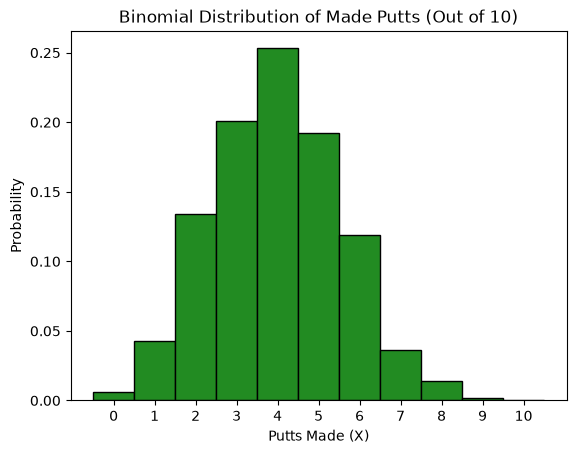

In [77]:
plt.hist(results, bins=range(0, 12), density=True, edgecolor='black', color='forestgreen', align='left')
plt.title("Binomial Distribution of Made Putts (Out of 10)")
plt.xlabel("Putts Made (X)")
plt.ylabel("Probability")
plt.xticks(range(0, 11))
plt.show()

## My Conclusion
Theoretical Probability of $X \ge 7$: $4\%$.

Estimated Probability of $X \ge 7$: Approximately $5.20\%$ from our 1,000 simulated trials. 

Mean (Expected Value): 3.98 putts ($10 \times 0.40 = 4.0$).

Standard Deviation: 1.55 putts ($\sqrt{10 \times 0.40 \times 0.60} \approx 1.55$).

Graph Interpretation: The graph peaks directly at $X = 4$, showing that making 4 putts is the single most likely result. Bars for $X \ge 7$ are very short, illustrating visually why scoring 7 or more made putts happens only about 5% of the time.